# rate_design v3 — the batch verdict (2026-09-08)

The 66-run declining-credit batch returned on 2026-09-08. This notebook
adjudicates every gate registered before the batch launched
(`methods.md` v2.1, v2.2, v2.2.1, v2.2.2) with the mechanics registered
before any output was read (`methods.md` v2.3). It reads only frozen
artifacts:

- the batch spec `u80`/`u81`/`u82`/`u84` (placement, offers, anchors, the
  pre-run GA predictions);
- the checks exports (`z-ethan/rate_design_checks/exports/`: delivery
  outcomes, trajectory gaps, the GX1 metric, the registry);
- the 49-case `step3_analysis` tables t08/t09 (the anchors' bills and rates);
- the stage-2 twin's band E5 and the v2 twin's secondary read u85, when they
  exist (the notebook runs once before the twins and once after).

Outputs: **u100** the per-run gate table; **u101** the verdict (the u91
schema, one row per gate plus the claim-ladder rung reached); **u102** the
GE2 boundary-depth read; **u103** the GH2 cap-depth read; **u104** GA2;
**u105** GA3; **u106** GX1; **u107** the five-anchor summary; figures
**w50–w54**.

The rules are applied as written. Nothing here re-argues a threshold, a
kill, or a rung after the outcomes.

Run this notebook on the **playground-env** kernel from `z-ethan/rate_design/`.

In [1]:
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))
import plotstyle as ps
ps.apply()
pd.set_option("display.width", 220)

HERE = Path.cwd()
assert HERE.name == "rate_design", f"run from z-ethan/rate_design/, not {HERE}"
REPO = HERE.parents[1]
EXPORTS = HERE / "exports"
FIGURES = HERE / "figures"
CHECKS_RD = REPO / "z-ethan" / "rate_design_checks" / "exports"
S3ANALYSIS = REPO / "z-ethan" / "step3_analysis" / "exports"
BRIDGE = REPO / "z-ethan" / "bridge_detection" / "exports"

SCHEDULES = ["eia", "aj", "iaea", "mck", "cop28", "eo"]
TOL_SHORT = 0.01
UNIT_MW = 300.0
W_PRIMARY = 2035
VERDICT = []          # (kind, name, result, detail) -> u101

# ---- R0: the checks registry has no FAIL in phases A, B, D, E --------------------
reg = pd.read_csv(CHECKS_RD / "checks_summary.csv")
fails = reg[(reg["status"] == "FAIL") & reg["phase"].isin(["A", "B", "D", "E"])]
assert not len(fails), fails
VERDICT.append(("gate", "R0", "PASS",
                f"rate_design_checks registry: {reg.status.value_counts().to_dict()}; no FAIL in A/B/D/E"))
GP_OK = bool(reg[reg["check"].str.startswith("GP:")]["status"].eq("PASS").all())
C4_OK = bool(reg[reg["check"].str.contains("dual conversion is correct")]["status"].eq("PASS").all())

# ---- frozen inputs -----------------------------------------------------------------
u80 = pd.read_csv(EXPORTS / "u80_batch_spec.csv")
u81 = pd.read_csv(EXPORTS / "u81_run_schedules.csv")
u82 = pd.read_csv(EXPORTS / "u82_anchor_spec.csv")
u84 = pd.read_csv(EXPORTS / "u84_anchor_predictions.csv")
u71 = pd.read_csv(EXPORTS / "u71_capture_decomposition.csv")
u73 = pd.read_csv(EXPORTS / "u73_no2050_sensitivity.csv")
outc = pd.read_csv(CHECKS_RD / "delivery_outcomes.csv")
gaps = pd.read_csv(CHECKS_RD / "trajectory_gaps.csv")
gx1c = pd.read_csv(CHECKS_RD / "gx1_horizon.csv")
t08 = pd.read_csv(S3ANALYSIS / "t08_rental_transfer.csv").set_index("case")
t09 = pd.read_csv(S3ANALYSIS / "t09_required_itc.csv")
assert len(outc) == 48 and set(outc["case"]) == set(u80[u80["block"] != "horizon"]["run"])
assert all(c in t08.index for c in u82["run"]), "t08 lacks the anchors: re-run step3_analysis"

def excess_of(note):
    m = re.search(r"cap 0\.\d0 excess ([+-]\d\.\d+)", str(note))
    return float(m.group(1)) if m else np.nan

u80["excess_at_cap"] = u80["note"].map(excess_of)
print(f"48 ITC-arm outcomes, 12 anchors, 6 horizon runs; GP {GP_OK}, C4 {C4_OK}")


48 ITC-arm outcomes, 12 anchors, 6 horizon runs; GP True, C4 True


## S1 — the per-run gate table (u100)

One row per ITC-arm run: the placement record from u80 (block, gate,
expected side, margin, cap, the excess at the cap for hybrids), the checks
outcome (tier, outcome, the gated years missed, the largest gated
shortfall, the 2050 delivered fraction), and the adjudication of a
deliver-side failure in the registered order: lumpiness (largest gated
shortfall below one 300 MW unit) → P1 (an eia delayed-start-recover run) →
true failure.

In [2]:
g = (outc.drop(columns=["block"])
     .merge(u80[["run", "block", "excess_at_cap", "note"]], left_on="case", right_on="run", how="left"))
assert set(g["block"]) == {"envelope", "boundary", "hybrid"}, set(g["block"])
def adjudicate(r):
    if r["delivers"]:
        return "delivers"
    if r["expected"] != "deliver":           # shortfall-side probe: non-delivery is the predicted outcome (v2.3: the clauses are GE1/GH1 only)
        return f"predicted shortfall: {r['outcome']}"
    if r["max_gated_shortfall_MW"] < UNIT_MW:
        return "lumpiness: counts as delivering (gap below one 300 MW unit)"
    if r["sched"] == "eia" and r["outcome"] == "delayed-start-recover":
        return "P1: eia delayed-start (certified fbC_eia precedent; arm-timing confound, reported)"
    return "true failure"
g["adjudication"] = g.apply(adjudicate, axis=1)
g["counts_as_delivering"] = g["adjudication"].isin(["delivers"]) | g["adjudication"].str.startswith("lumpiness")
u100 = g[["case", "block", "gate", "expected", "sched", "mult", "cap", "draw_index", "margin_ratepts",
          "target_ratepts", "excess_at_cap", "deficit_years_spec", "tier", "outcome", "delivers",
          "counts_as_delivering", "adjudication", "miss_years", "max_gated_shortfall_MW",
          "first_build_year", "smr_2050_MW", "traj_2050_MW", "delivered_frac_2050"]].copy()
u100.to_csv(EXPORTS / "u100_gate_table.csv", index=False)
print(u100[["case", "gate", "expected", "margin_ratepts", "excess_at_cap", "outcome",
            "counts_as_delivering", "adjudication", "delivered_frac_2050"]].to_string(index=False))


            case gate  expected  margin_ratepts  excess_at_cap               outcome  counts_as_delivering                                                                       adjudication  delivered_frac_2050
   fb_aj_m100_cw  GE1   deliver         -0.0420            NaN         full-delivery                  True                                                                           delivers              11.2350
   fb_aj_m100_mg  GE1   deliver         -0.0100            NaN         full-delivery                  True                                                                           delivers              10.3412
   fb_aj_m100_ju  GE2 shortfall          0.0100            NaN         full-delivery                  True                                                                           delivers               8.9410
   fb_aj_m150_cw  GE1   deliver         -0.0824            NaN         full-delivery                  True                                                  

## S2 — GE1 and GH1: the deliver side

GE1: all 18 deliver-side envelope runs (9 comfortable, 9 marginal at −1
point) deliver. GH1: all 6 cap-never-binds hybrids deliver. A true failure
on either side fails the shaped-schedule certificate outright (v2.1); P1
failures are reported, not scored.

In [3]:
def side_verdict(gate):
    sub = u100[u100["gate"] == gate]
    true_fail = sub[sub["adjudication"] == "true failure"]
    p1 = sub[sub["adjudication"].str.startswith("P1")]
    lump = sub[sub["adjudication"].str.startswith("lumpiness")]
    result = "PASS" if not len(true_fail) else "FAIL"
    det = (f"{int(sub['counts_as_delivering'].sum())} of {len(sub)} deliver-side runs deliver"
           + (f"; lumpiness-adjudicated: {lump['case'].tolist()}" if len(lump) else "")
           + (f"; P1 (eia delayed-start, reported): {p1['case'].tolist()}" if len(p1) else "")
           + (f"; TRUE FAILURES: " + ", ".join(f"{r.case} ({r.delivered_frac_2050:.2f} of the 2050 target)"
                                                for r in true_fail.itertuples()) if len(true_fail) else ""))
    return result, det, true_fail
ge1, ge1_det, ge1_fail = side_verdict("GE1")
gh1, gh1_det, gh1_fail = side_verdict("GH1")
VERDICT.append(("gate", "GE1", ge1, ge1_det))
VERDICT.append(("gate", "GH1", gh1, gh1_det))
print("GE1", ge1, "--", ge1_det)
print("GH1", gh1, "--", gh1_det)
# per-schedule reading (a finding, not a gate)
per = (u100[u100["gate"].isin(["GE1", "GH1"])].groupby("sched")
       .apply(lambda d: f"{int(d['counts_as_delivering'].sum())}/{len(d)}").to_dict())
VERDICT.append(("finding", "deliver-side-by-schedule", "REPORTED",
                "deliver-side runs delivering, per schedule: " + str({s: per[s] for s in SCHEDULES})))


GE1 FAIL -- 14 of 18 deliver-side runs deliver; P1 (eia delayed-start, reported): ['fb_eia_m150_mg']; TRUE FAILURES: fb_eo_m100_mg (0.31 of the 2050 target), fb_eo_m150_mg (0.65 of the 2050 target), fb_cop28_m150_mg (0.80 of the 2050 target)
GH1 FAIL -- 4 of 6 deliver-side runs deliver; P1 (eia delayed-start, reported): ['hy_eia_nb']; TRUE FAILURES: hy_eo_nb (0.53 of the 2050 target)


C:\Users\ethan\AppData\Local\Temp\ipykernel_25760\1056000083.py:21: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda d: f"{int(d['counts_as_delivering'].sum())}/{len(d)}").to_dict())


## S3 — GE2: the boundary depth (shortfall side)

Per schedule and budget, the shortfall-side probes are ordered by their u80
margin (+1 just-uncovered, +3 deep, +5 far) with the −1 marginal run as the
deliver-side end of the same ladder (v2.3). The read reports the deepest
delivering probe and the shallowest non-delivering probe; the probe spacing
is the error bar. Registered readings: a ladder whose deepest probe delivers
is "offline criterion conservative beyond the r03 bracket"; a ladder whose
+1 probe fails is "sharp to the cushion"; a ladder whose −1 run fails puts
the boundary inside the covered set.

In [4]:
# GA3's registered consequence (v2.2.1/v2.3): where an anchor's per-year rate error exceeds 5 points, the GE2 depth
# reads carry the measured map error as an additional error bar. Per schedule = max |error| over its two anchors'
# rate-bearing years; reported in u102. The GA3 gate itself is adjudicated in S5.
_t09r = t09[t09["status"] == "rate"].set_index(["case", "t"])["i_model_headline"]
MAPERR = {}
for r in u84.itertuples():
    key = (r.run, int(r.year))
    if key in _t09r.index:
        e = abs(100 * (r.pred_rate - float(_t09r.loc[key])))
        MAPERR[r.schedule] = max(MAPERR.get(r.schedule, 0.0), e)
MAPERR = {k: round(v, 1) for k, v in MAPERR.items()}
print("GA3 map error per schedule (max |pts| over the two anchors):", MAPERR)
rows102 = []
env = u100[u100["block"].isin(["envelope", "boundary"])].copy()
env["tag"] = env["case"].str.split("_").str[-1]
for (ab, mult), d in env.groupby(["sched", "mult"]):
    d = d.sort_values("margin_ratepts")
    # boundary probes at 1.5x belong to that ladder (their u80 mult is 1.5)
    deliv = d[d["counts_as_delivering"]]
    fail = d[~d["counts_as_delivering"]]
    deepest_ok = float(deliv["margin_ratepts"].max()) if len(deliv) else np.nan
    shallowest_fail = float(fail["margin_ratepts"].min()) if len(fail) else np.nan
    tags_ok = deliv["tag"].tolist()
    tags_fail = fail["tag"].tolist()
    mg_ok = bool(d[d["tag"] == "mg"]["counts_as_delivering"].all()) if (d["tag"] == "mg").any() else None
    ju_ok = bool(d[d["tag"] == "ju"]["counts_as_delivering"].all()) if (d["tag"] == "ju").any() else None
    deepest_probe = d[d["tag"].isin(["p3", "p5", "ju"])].sort_values("margin_ratepts").iloc[-1]
    has_depth = deepest_probe["tag"] in ("p3", "p5")          # the registered flag needs the +5 (or +3) probe
    probes = d[d["tag"] != "cw"].sort_values("margin_ratepts")
    monotone = bool((probes["counts_as_delivering"].astype(int).diff().dropna() <= 0).all())
    # registered readings (methods.md v2.3): "conservative beyond the r03 bracket" iff the deepest depth probe delivers;
    # "sharp to the cushion" iff the +1 probe fails; otherwise the interval between the deepest delivering and the
    # shallowest failing probe. The -1 marginal run's failure is a GE1 matter: annotated, never a label of its own.
    if has_depth and bool(deepest_probe["counts_as_delivering"]):
        reading = "conservative beyond the r03 bracket: the deepest probe delivers (%s at +%.0f pts)" % (
            deepest_probe["tag"], 100 * deepest_probe["margin_ratepts"])
    elif ju_ok is False:
        reading = "sharp to the cushion: the +1 probe fails"
    elif not len(fail):
        reading = "every probe delivers; no depth probe at this budget (deepest +%.0f pts, inside the r03 bracket)" % (
            100 * deepest_probe["margin_ratepts"])
    else:
        reading = "boundary between +%.0f (delivers) and +%.0f (fails) pts" % (100 * deepest_ok, 100 * shallowest_fail)
    if mg_ok is False:
        reading += "; the -1-point marginal run also fails (GE1 true failure or P1)"
    if not monotone:
        reading += "; NON-MONOTONE ladder (a deeper probe delivers where a shallower one fails)"
    rows102.append(dict(schedule=ab, mult=mult, n_probes=len(d), delivering=tags_ok, failing=tags_fail,
                        deepest_delivering_margin=deepest_ok, shallowest_failing_margin=shallowest_fail,
                        probe_spacing_pts=2.0, map_error_pts=MAPERR.get(ab, np.nan),
                        error_bar_pts=max(2.0, MAPERR.get(ab, 0.0)), monotone=monotone, reading=reading,
                        frac2050=dict(zip(d["tag"], d["delivered_frac_2050"].round(3)))))
u102 = pd.DataFrame(rows102)
u102.to_csv(EXPORTS / "u102_ge2_depth.csv", index=False)
print(u102[["schedule", "mult", "delivering", "failing", "reading"]].to_string(index=False))
n_cons = int(u102["reading"].str.startswith("conservative").sum())
n_sharp = int(u102["reading"].str.startswith("sharp").sum())
n_nodepth = int(u102["reading"].str.startswith("every probe delivers; no depth").sum())
n_between = int(u102["reading"].str.startswith("boundary between").sum())
n_mgfail = int(u102["reading"].str.contains("marginal run also fails").sum())
n_nonmono = int((~u102["monotone"]).sum())
n_inside = n_mgfail   # for the ladder-rung logic below: a -1 failure is a GE1 true failure or P1
VERDICT.append(("gate", "GE2", "MEASURED",
                f"{len(u102)} schedule x budget ladders: {n_cons} conservative beyond the r03 bracket (the +3 probe "
                f"delivers: {u102[u102['reading'].str.startswith('conservative')][['schedule', 'mult']].values.tolist()}), "
                f"{n_sharp} sharp to the cushion (the +1 probe fails), {n_between} with the boundary between +1 and +3, "
                f"{n_nodepth} with every probe delivering but no depth probe at that budget (1.0x ladders); "
                f"{n_mgfail} ladders whose -1 marginal run also fails (a GE1 matter); {n_nonmono} non-monotone; "
                f"error bar = max(2-pt probe spacing, the GA3 map error per schedule {MAPERR}) -- the GA3 consequence "
                "registered in v2.2.1/v2.3; measured, never pass/fail (v2.1)"))
if n_cons:
    VERDICT.append(("consequence", "GE2-contour-claims", "WITHDRAWN",
                    "at least one +3/+5 probe delivers => the offline criterion is conservative beyond the r03 "
                    "bracket there; contour-shape claims are withdrawn and capture numbers survive only as "
                    "lower bounds (v2.1 registration)"))


GA3 map error per schedule (max |pts| over the two anchors): {'eia': 9.4, 'aj': 9.6, 'iaea': 12.7, 'mck': 14.6, 'cop28': 16.1, 'eo': 19.1}
schedule  mult       delivering          failing                                                                                                                                                                                      reading
      aj   1.0     [cw, mg, ju]               []                                                                                                 every probe delivers; no depth probe at this budget (deepest +1 pts, inside the r03 bracket)
      aj   1.5 [cw, mg, ju, p3]               []                                                                                                               conservative beyond the r03 bracket: the deepest probe delivers (p3 at +3 pts)
   cop28   1.5         [cw, ju]         [mg, p3] boundary between +1 (delivers) and +-1 (fails) pts; the -1-point marginal run also fails (GE1 true

## S4 — GH2: the cap dimension

Per cap, the cap-binds probes are read as a depth ladder on the u80
post-window excess (0.60: eia +3, cop28 +1, eo +1/+2; 0.50: mck +1, aj +3,
iaea +5, eo +5), with the 0.60 cap-never-binds runs as the only deliver-side
control. Never re-scored on any other basis; a demonstration, not a
certification. The eia hybrids are pure capped credit (no window).

In [5]:
hy = u100[u100["block"] == "hybrid"].copy()
hy["tag"] = hy["case"].str.split("_").str[-1]
rows103 = []
for cap, d in hy.groupby("cap"):
    d = d.sort_values("excess_at_cap")
    for r in d.itertuples():
        rows103.append(dict(cap=cap, schedule=r.sched, run=r.case, tag=r.tag, expected=r.expected,
                            excess_at_cap=r.excess_at_cap, delivers=r.counts_as_delivering,
                            adjudication=r.adjudication, outcome=r.outcome,
                            delivered_frac_2050=r.delivered_frac_2050,
                            note=("no deliver-side control at this cap (directional)" if cap == 0.5 else "")))
u103 = pd.DataFrame(rows103)
u103.to_csv(EXPORTS / "u103_gh2_cap_depth.csv", index=False)
print(u103[["cap", "run", "expected", "excess_at_cap", "delivers", "adjudication", "delivered_frac_2050"]]
      .to_string(index=False))
cb = u103[u103["expected"] == "shortfall"]
cb_del = cb[cb["delivers"]]
ctrl = u103[u103["tag"] == "nb"].set_index("schedule")
ctrl_txt = {ab: ("delivers" if bool(ctrl.loc[ab, "delivers"]) else str(ctrl.loc[ab, "adjudication"])[:24]) for ab in ctrl.index}
cb_attrib = [r.run for r in cb.itertuples() if (not r.delivers) and bool(ctrl.loc[r.schedule, "delivers"])]
VERDICT.append(("gate", "GH2", "MEASURED",
                f"read against the 0.60 cap-never-binds control per schedule (controls: {ctrl_txt}): cap-attributable "
                f"shortfalls = cap-binds probes failing where their control delivers = {cb_attrib or 'NONE'}; every eo "
                "shortfall shares the failing eo control (not attributable to the cap) and eia's control is the P1 "
                f"delayed-start shape; cap-binds probes delivering: {len(cb_del)} of {len(cb)} -- "
                + "; ".join(f"{r.run} (cap {r.cap:.2f}, excess {r.excess_at_cap:+.3f}): "
                            f"{'delivers' if r.delivers else r.outcome} {r.delivered_frac_2050:.2f}"
                            for r in cb.itertuples())
                + "; the 0.50 block has no deliver-side control (directional); aj/mck/iaea 0.60 pools empty "
                "(reportable); a demonstration, not a certification"))


 cap          run  expected  excess_at_cap  delivers                                                                       adjudication  delivered_frac_2050
 0.5  hy_mck_cb50 shortfall          0.010      True                                                                           delivers               2.1606
 0.5   hy_aj_cb50 shortfall          0.030      True                                                                           delivers               9.5813
 0.5 hy_iaea_cb50 shortfall          0.050      True                                                                           delivers               4.5572
 0.5   hy_eo_cb50 shortfall          0.052     False                                                predicted shortfall: under-delivery               0.4010
 0.6  hy_cop28_nb   deliver         -0.263      True                                                                           delivers               1.9129
 0.6    hy_mck_nb   deliver         -0.201      True      

## S5 — GA1, GA2, GA3: the anchors

GA1: each p25/p75 anchor's bill reproduces the t08 convention on its own h5
(the checks' dual-conversion audit C4 and the port-fidelity gate GP, then
the 49-case step3_analysis t08). GA2: the three-anchor map's pre-run bill
prediction (u84) against the anchor's t08 bill, ±10% informative, ±20% the
certificate. GA3: the pre-run per-year rate prediction against the anchor's
own t09 rate, |error| ≤ 5 points every rate-bearing year validates the
batch's probe placement to the r03 bracket (not to the 2-point probe
spacing).

In [6]:
_b13 = BRIDGE / "b13_verdict_5a.csv"
G1_EXT = None
if _b13.exists():
    _b = pd.read_csv(_b13).set_index("metric")["value"]
    G1_EXT = str(_b.loc["g1_t08_reproduced"]) == "True"
ga1 = "PASS" if (GP_OK and C4_OK and (G1_EXT is not False)) else "FAIL"
VERDICT.append(("gate", "GA1", ga1,
                f"12 anchors: the G1 bill check extended to every t08 case incl. the anchors (stage-2 twin b13 "
                f"g1_t08_reproduced = {G1_EXT if G1_EXT is not None else 'pending (twin not yet run)'}; each anchor bill "
                f"within 0.051 $B of its t08 row); dual-conversion audit C4 {'PASS' if C4_OK else 'FAIL'}; port fidelity GP "
                f"{'PASS' if GP_OK else 'FAIL'}; t08 rows present for all 12 (49-case step3_analysis)"))
rows104 = []
for r in u84.drop_duplicates("run").itertuples():
    true = float(t08.loc[r.run, "PV_rental_transfer_2024B"])
    err = (r.pred_bill_2050_2024B - true) / true
    rows104.append(dict(run=r.run, schedule=r.schedule, percentile=r.percentile, draw_index=r.draw_index,
                        pred_bill_2024B=r.pred_bill_2050_2024B, true_bill_2024B=true,
                        signed_rel_err=round(err, 4), within_10pct=abs(err) <= 0.10, within_20pct=abs(err) <= 0.20))
u104 = pd.DataFrame(rows104)
u104.to_csv(EXPORTS / "u104_ga2_bills.csv", index=False)
print(u104.to_string(index=False))
ga2 = "PASS" if u104["within_20pct"].all() else "FAIL"
VERDICT.append(("gate", "GA2", ga2,
                f"three-anchor bill map vs the 12 new anchors: signed errors "
                f"{u104['signed_rel_err'].min():+.3f} to {u104['signed_rel_err'].max():+.3f}; "
                f"{int(u104['within_20pct'].sum())}/12 inside +/-20% (the certificate), "
                f"{int(u104['within_10pct'].sum())}/12 inside +/-10% (informative); outside 10%: "
                f"{u104[~u104['within_10pct']]['run'].tolist()}"))

t09r = t09[t09["status"] == "rate"].set_index(["case", "t"])
rows105 = []
for r in u84.itertuples():
    key = (r.run, int(r.year))
    if key in t09r.index:
        true = float(t09r.loc[key, "i_model_headline"])
        rows105.append(dict(run=r.run, schedule=r.schedule, percentile=r.percentile, year=int(r.year),
                            pred_rate=r.pred_rate, true_rate=true, err_ratepts=round(100 * (r.pred_rate - true), 2),
                            status="rate", upper_clamped=r.upper_clamped))
    else:
        st = t09[(t09["case"] == r.run) & (t09["t"] == int(r.year))]["status"]
        rows105.append(dict(run=r.run, schedule=r.schedule, percentile=r.percentile, year=int(r.year),
                            pred_rate=r.pred_rate, true_rate=np.nan, err_ratepts=np.nan,
                            status=(st.iloc[0] if len(st) else "not mandated"), upper_clamped=r.upper_clamped))
u105 = pd.DataFrame(rows105)
u105.to_csv(EXPORTS / "u105_ga3_rates.csv", index=False)
r105 = u105[u105["status"] == "rate"]
per_anchor = r105.groupby("run")["err_ratepts"].agg(lambda s: float(np.abs(s).max()))
ok_anchor = per_anchor <= 5.0
print(per_anchor.round(2).to_string())
ga3 = "PASS" if ok_anchor.all() else "PARTIAL"
VERDICT.append(("gate", "GA3", ga3,
                f"per-year rate error at the 12 anchors: max |err| {per_anchor.max():.1f} pts "
                f"(median over rate cells {r105['err_ratepts'].abs().median():.1f}); anchors within 5 pts every "
                f"rate-bearing year: {int(ok_anchor.sum())}/12"
                + (f"; outside: " + str({k: round(v, 1) for k, v in per_anchor[~ok_anchor].items()}) if not ok_anchor.all() else "")
                + "; a pass validates placement to the r03 bracket, not to the 2-pt probe spacing (N3); "
                  "where an anchor fails, the GE2 depth reads carry the map error as an extra error bar"))


             run schedule percentile  draw_index  pred_bill_2024B  true_bill_2024B  signed_rel_err  within_10pct  within_20pct
  smr100_eia_p25      eia        p25        7498            16.98             17.2         -0.0128          True          True
  smr100_eia_p75      eia        p75        6540            47.66             45.8          0.0406          True          True
   smr100_aj_p25       aj        p25        3569            20.89             21.2         -0.0146          True          True
   smr100_aj_p75       aj        p75        9504            40.38             44.3         -0.0885          True          True
 smr100_iaea_p25     iaea        p25         516            68.82             60.2          0.1432         False          True
 smr100_iaea_p75     iaea        p75        7323           152.80            147.7          0.0345          True          True
  smr100_mck_p25      mck        p25        3229            59.51             67.4         -0.1171         Fals

## S6 — GX1: the terminal-year diagnostic

Per schedule: the extended run (end year 2055, mandate flat after 2050)
sheds at least half of the anchor's 2047→2050 required-rate uptick → the
uptick is an end-of-horizon artifact and the no-2050 basis (u73) is
reported; otherwise the 2050 barbell is a real terminal effect and the
with-2050 basis stands. The checks notebook computed the metric with the
ported t09 code on each run's own h5; this cell applies the rule.

In [7]:
u106 = gx1c.copy()
u106["basis"] = np.where(u106["shed_fraction"] >= 0.5, "no-2050 (u73)", "with-2050 (u71)")
u106.to_csv(EXPORTS / "u106_gx1.csv", index=False)
print(u106[["schedule", "uptick_std", "uptick_ext", "shed_fraction", "max_abs_rate_diff_2031_2047",
            "verdict", "basis"]].to_string(index=False))
n_art = int((u106["shed_fraction"] >= 0.5).sum())
VERDICT.append(("gate", "GX1", "PERSISTS" if n_art == 0 else f"ARTIFACT-{n_art}",
                f"extended runs shed {u106['shed_fraction'].min():.2f}-{u106['shed_fraction'].max():.2f} of the "
                f"2047->2050 uptick (rule: >= 0.5 = artifact): {n_art} of 6 schedules artifact; pre-terminal rates "
                f"identical to the anchors (max |diff| {u106['max_abs_rate_diff_2031_2047'].max():.3f}); reading: the "
                "uptick is NOT an end-of-horizon artifact of the solve -- under the sequential/myopic solve the 2050 LP "
                "has no dependence on later years, which the identity verifies (to 3 decimals) rather than assumes; the "
                "extension could only have moved 2050 if ReEDS carried a hidden terminal treatment, so the diagnostic "
                "says nothing about the mandate/cost path itself; the with-2050 basis is retained by the registered "
                "default; no fb_/bd_ probe is re-scored"))


schedule  uptick_std  uptick_ext  shed_fraction  max_abs_rate_diff_2031_2047                   verdict           basis
     eia       0.054       0.054            0.0                          0.0 persists: with-2050 basis with-2050 (u71)
      aj       0.059       0.059            0.0                          0.0 persists: with-2050 basis with-2050 (u71)
    iaea       0.068       0.068            0.0                          0.0 persists: with-2050 basis with-2050 (u71)
     mck       0.033       0.033            0.0                          0.0 persists: with-2050 basis with-2050 (u71)
   cop28       0.079       0.079            0.0                          0.0 persists: with-2050 basis with-2050 (u71)
      eo       0.045       0.045            0.0                          0.0 persists: with-2050 basis with-2050 (u71)


## S7 — the claim ladder, the capture rule, and the findings

The ladder is applied as registered (v2.1 + the v2.2 GA rung). Full pass
needs GE1 + GE2-full + GH1 + GH2; a GE1 true failure is the "fail" rung:
the Part B baseline stands unchanged and the failure is reported as a
measured limit of offline schedule design. K1 fired before launch and
stands: no in-sample capture number is ever quoted; the holdout-scored
greedy capture is quotable only on a surviving rung.

In [8]:
if ge1 == "PASS" and gh1 == "PASS" and n_cons == 0 and n_inside == 0:
    rung = "FULL"
elif ge1 == "PASS":
    rung = "PARTIAL"
else:
    rung = "FAIL"
VERDICT.append(("ladder", "rung", rung,
                {"FULL": "shaped-schedule delivery model-certified; capture gains quotable (holdout-scored, K1 rule)",
                 "PARTIAL": "bounded certificate: delivery certified within N rate points of the offline boundary; "
                            "only contour claims inside that bound quotable",
                 "FAIL": "GE1 broken: the Part B baseline stands unchanged; the failures are reported as a measured "
                         "limit of offline schedule design; capture numbers are NOT quotable; the delivery outcomes "
                         "are reportable as findings"}[rung]))
VERDICT.append(("rule", "K1-quoting", "STANDS",
                "no in-sample capture numeral is quoted; on the FAIL rung no capture number is quoted at all; "
                f"for the record the holdout-scored greedy capture would be in-sample minus the worst split drop "
                f"({float(u71['holdout_drop_worst'].max()):.3f}), quantile companion beside it"))

# findings from the outcomes (reportable regardless of the rung)
dl = u100[u100["counts_as_delivering"] & u100["block"].isin(["envelope", "boundary"])]
VERDICT.append(("finding", "induced-take-up", "REPORTED",
                f"the {len(dl)} delivering envelope/boundary runs build "
                f"{dl['delivered_frac_2050'].min():.2f}-{dl['delivered_frac_2050'].max():.2f}x their 2050 target "
                f"(median {dl['delivered_frac_2050'].median():.2f}x): a credit path that covers a world induces "
                "take-up far above the target, so the every-world outlay bound needs the allocation cap "
                "(v1 audit finding 2 confirmed in the model)"))
big = u100[(u100["gate"] == "GE1") & (u100["adjudication"] == "true failure")]
VERDICT.append(("finding", "cliff-schedules", "REPORTED",
                "true GE1 failures: " + ", ".join(f"{r.case} {r.delivered_frac_2050:.2f}" for r in big.itertuples())
                + " -- on the three-anchor map these worlds sat one rate point inside the covered set; the comfortable "
                  "runs of the same schedules deliver. Disclosed secondary read (u85, never scored): on the five-anchor "
                  "map fb_eo_m150_mg and fb_cop28_m150_mg are predicted uncovered (margins +0.011 / +0.033) -- the "
                  "three-anchor placement, not the model, put them on the deliver side"))
# per-schedule synthesis
syn = {}
for ab in SCHEDULES:
    d = u100[u100["sched"] == ab]
    syn[ab] = f"{int(d['counts_as_delivering'].sum())}/{len(d)} runs deliver"
VERDICT.append(("finding", "runs-delivering-by-schedule", "REPORTED", str(syn)))


## S8 — the five-anchor twins (E5 and the secondary read)

Filled in on the second run, after the stage-2 twin (E5) and the v2 twin
(u85) exist. The outcomes are fixed in `methods.md` v2.3: E5 ≤ 0.10 → the
mask's range framing is re-quoted at the five-anchor width; 0.10 < E5 ≤ 0.20
→ reported, framing unchanged in kind; E5 > 0.20 → sensitivity only.

In [9]:
rows107 = []
b07_5a = BRIDGE / "b07_bill_attachment_5a.csv"
if b07_5a.exists():
    b7 = pd.read_csv(b07_5a)
    E5 = float(b7["band_e5"].iloc[0])
    outcome = ("mask range re-quoted at the five-anchor width" if E5 <= 0.10 else
               "reported; framing unchanged in kind" if E5 <= 0.20 else
               "five-anchor map not better certified; twins are a sensitivity only")
    for r in b7.itertuples():
        rows107.append(dict(schedule=r.schedule, loo_err_p25=r.loo_err_p25, loo_err_p50=r.loo_err_p50,
                            loo_err_p75=r.loo_err_p75, loo_max_abs_err=r.loo_max_abs_err, band_e5=E5))
    VERDICT.append(("gate", "E5", f"{E5:.2f}",
                    f"five-anchor leave-one-out band E5 = {E5:.2f} (max |LOO bill error| over 18 pairs "
                    f"{b7['loo_max_abs_err'].max():.3f}; three-anchor hide-the-middle band was 0.20): {outcome}"))
    repoint = (ga1 == "PASS" and ga2 == "PASS" and E5 <= 0.20)
    VERDICT.append(("decision", "display-basis", "FIVE-ANCHOR" if repoint else "THREE-ANCHOR",
                    ("GA1 PASS, GA2 inside +/-20%, E5 <= 0.20: Fig 5b / Fig 6a / Fig 6b and ST14/ST16 read the "
                     "_5a twins (Ethan's 2026-09-08 ruling); S4's market-world transfer stays three-anchor"
                     if repoint else "conditions not met: displays stay three-anchor, GA outcome disclosed")))
else:
    VERDICT.append(("gate", "E5", "PENDING", "stage-2 twin not yet executed (b07_bill_attachment_5a.csv absent)"))
u85p = EXPORTS / "u85_remargin_5a.csv"
if u85p.exists():
    u85 = pd.read_csv(u85p)
    flips = u85[u85["side_3a"] != u85["side_5a"]]
    VERDICT.append(("secondary", "GE2-5a-remargin", "DISCLOSED",
                    f"five-anchor re-margining of the 48 run worlds: {len(flips)} side flips "
                    f"({flips['run'].tolist()}); |d margin| median {u85['d_margin'].abs().median():.3f}, "
                    f"max {u85['d_margin'].abs().max():.3f} rate points; never used for scoring"))
else:
    VERDICT.append(("secondary", "GE2-5a-remargin", "PENDING", "v2 twin not yet executed (u85 absent)"))
u107 = pd.DataFrame(rows107)
u107.to_csv(EXPORTS / "u107_five_anchor_summary.csv", index=False)
print(u107.to_string(index=False) if len(u107) else "E5 pending")


schedule  loo_err_p25  loo_err_p50  loo_err_p75  loo_max_abs_err  band_e5
     eia       -0.012       -0.011        0.040            0.040     0.18
      aj       -0.015        0.129       -0.088            0.129     0.18
    iaea        0.143       -0.149        0.034            0.149     0.18
     mck       -0.117        0.010       -0.018            0.117     0.18
   cop28       -0.057       -0.009        0.007            0.057     0.18
      eo        0.089        0.177       -0.146            0.177     0.18


## S9 — the verdict table (u101)

In [10]:
u101 = pd.DataFrame(VERDICT, columns=["kind", "name", "result", "detail"])
u101.to_csv(EXPORTS / "u101_verdict.csv", index=False)
with pd.option_context("display.max_colwidth", 400):
    print(u101.to_string(index=False))


       kind                        name      result                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                     

## S10 — figures

- **w50** the delivery ladders: per schedule, the 2050 delivered fraction of
  every envelope and boundary run against its u80 margin (negative = covered
  with slack); filled markers deliver, open markers do not; the offline
  boundary is the vertical line at zero.
- **w51** the cap ladder: the hybrid runs against their post-window excess at
  the cap.
- **w52** GX1: the standard and the extended run's required-rate paths.
- **w53** GA2 and GA3: predicted against true anchor bills, and the per-year
  rate errors.
- **w54** (second run only) the five-anchor mask beside the three-anchor
  mask.

saved -> figures\w50_delivery_ladders.png


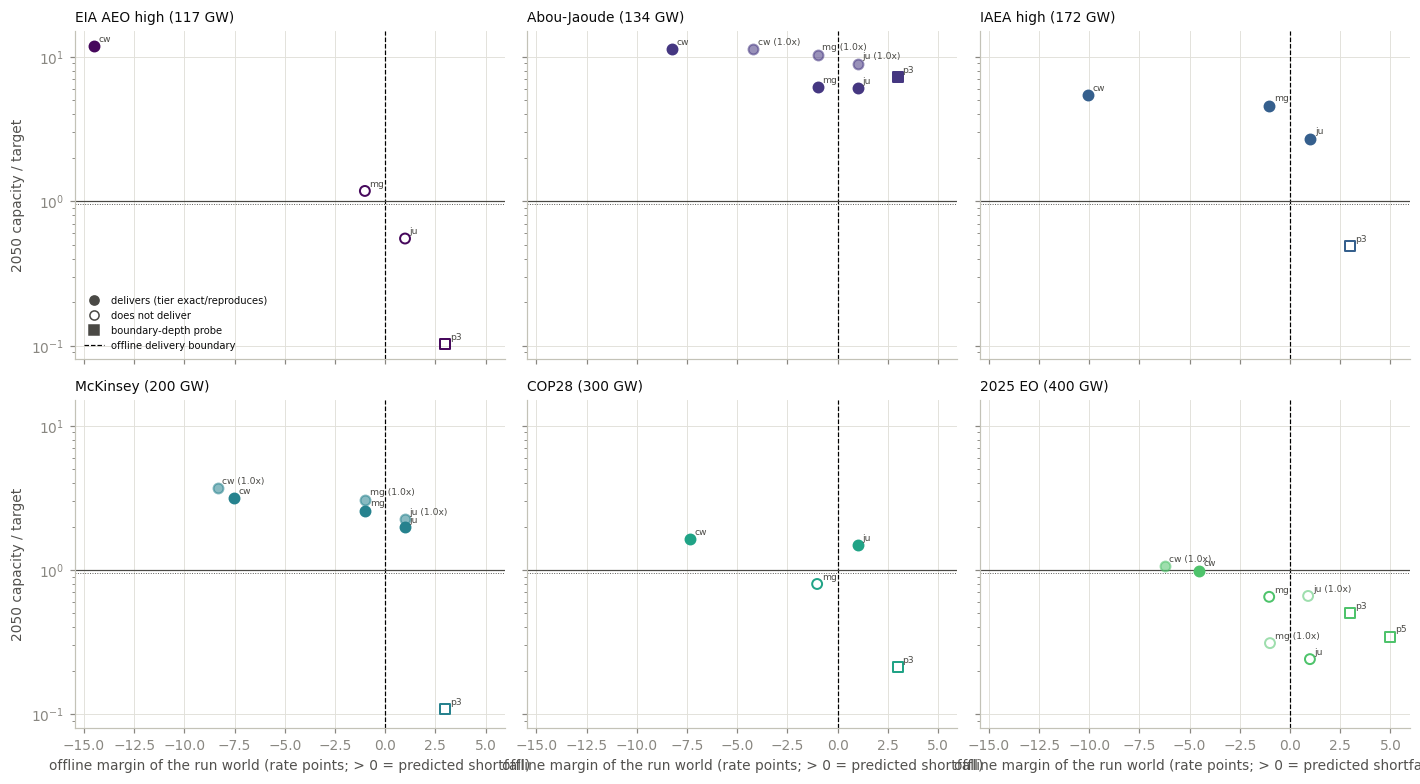

saved -> figures\w51_cap_ladder.png


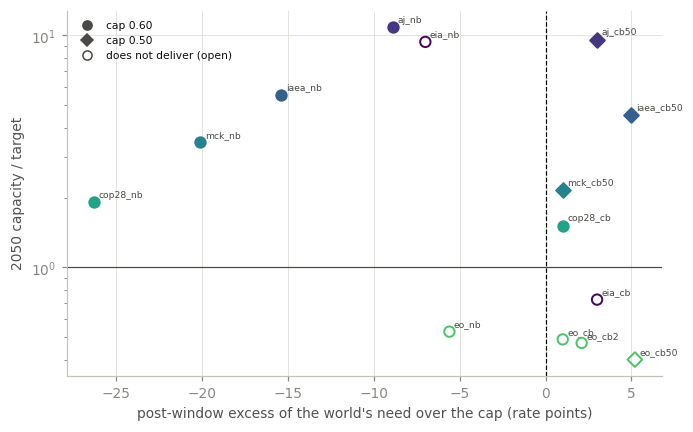

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(ps.W3, 7.2), sharex=True, sharey=True)
MK = {"envelope": "o", "boundary": "s"}
for ax, ab in zip(axes.flat, SCHEDULES):
    d = u100[(u100["sched"] == ab) & u100["block"].isin(["envelope", "boundary"])]
    for r in d.itertuples():
        ax.scatter(100 * r.margin_ratepts, r.delivered_frac_2050, marker=MK[r.block], s=42,
                   facecolors=(ps.SCHED_C[ab] if r.counts_as_delivering else "none"),
                   edgecolors=ps.SCHED_C[ab], linewidths=1.3, zorder=3,
                   alpha=(1.0 if r.mult == 1.5 else 0.55))
        ax.annotate(r.case.split("_")[-1] + ("" if r.mult == 1.5 else " (1.0x)"),
                    (100 * r.margin_ratepts, r.delivered_frac_2050), xytext=(3, 3),
                    textcoords="offset points", fontsize=6, color=ps.BASE_C)
    ax.axvline(0, color="k", lw=0.8, ls="--")
    ax.axhline(1.0, color=ps.BASE_C, lw=0.8)
    ax.axhline(0.95, color=ps.BASE_C, lw=0.6, ls=":")
    ax.set_yscale("log")
    ax.set_title(ps.SCHED_LABEL[ab], fontsize=9)
for ax in axes[1]:
    ax.set_xlabel("offline margin of the run world (rate points; > 0 = predicted shortfall)")
for ax in axes[:, 0]:
    ax.set_ylabel("2050 capacity / target")
from matplotlib.lines import Line2D
axes.flat[0].legend([Line2D([], [], marker="o", color=ps.BASE_C, ls="none"),
                     Line2D([], [], marker="o", mfc="none", color=ps.BASE_C, ls="none"),
                     Line2D([], [], marker="s", color=ps.BASE_C, ls="none"),
                     Line2D([], [], color="k", lw=0.8, ls="--")],
                    ["delivers (tier exact/reproduces)", "does not deliver", "boundary-depth probe",
                     "offline delivery boundary"], fontsize=6.5, loc="lower left")
fig.tight_layout()
ps.savefig(fig, FIGURES / "w50_delivery_ladders.png")
plt.show()

fig, ax = plt.subplots(figsize=(ps.W1, 4.0))
for r in u103.itertuples():
    ax.scatter(100 * r.excess_at_cap, r.delivered_frac_2050, marker=("o" if r.cap == 0.6 else "D"), s=46,
               facecolors=(ps.SCHED_C[r.schedule] if r.delivers else "none"), edgecolors=ps.SCHED_C[r.schedule],
               linewidths=1.3, zorder=3)
    ax.annotate(r.run.replace("hy_", ""), (100 * r.excess_at_cap, r.delivered_frac_2050), xytext=(3, 3),
                textcoords="offset points", fontsize=6, color=ps.BASE_C)
ax.axvline(0, color="k", lw=0.8, ls="--")
ax.axhline(1.0, color=ps.BASE_C, lw=0.8)
ax.set_yscale("log")
ax.set_xlabel("post-window excess of the world's need over the cap (rate points)")
ax.set_ylabel("2050 capacity / target")
ax.legend([Line2D([], [], marker="o", color=ps.BASE_C, ls="none"),
           Line2D([], [], marker="D", color=ps.BASE_C, ls="none"),
           Line2D([], [], marker="o", mfc="none", color=ps.BASE_C, ls="none")],
          ["cap 0.60", "cap 0.50", "does not deliver (open)"], fontsize=7)
fig.tight_layout()
ps.savefig(fig, FIGURES / "w51_cap_ladder.png")
plt.show()


saved -> figures\w52_gx1_horizon.png


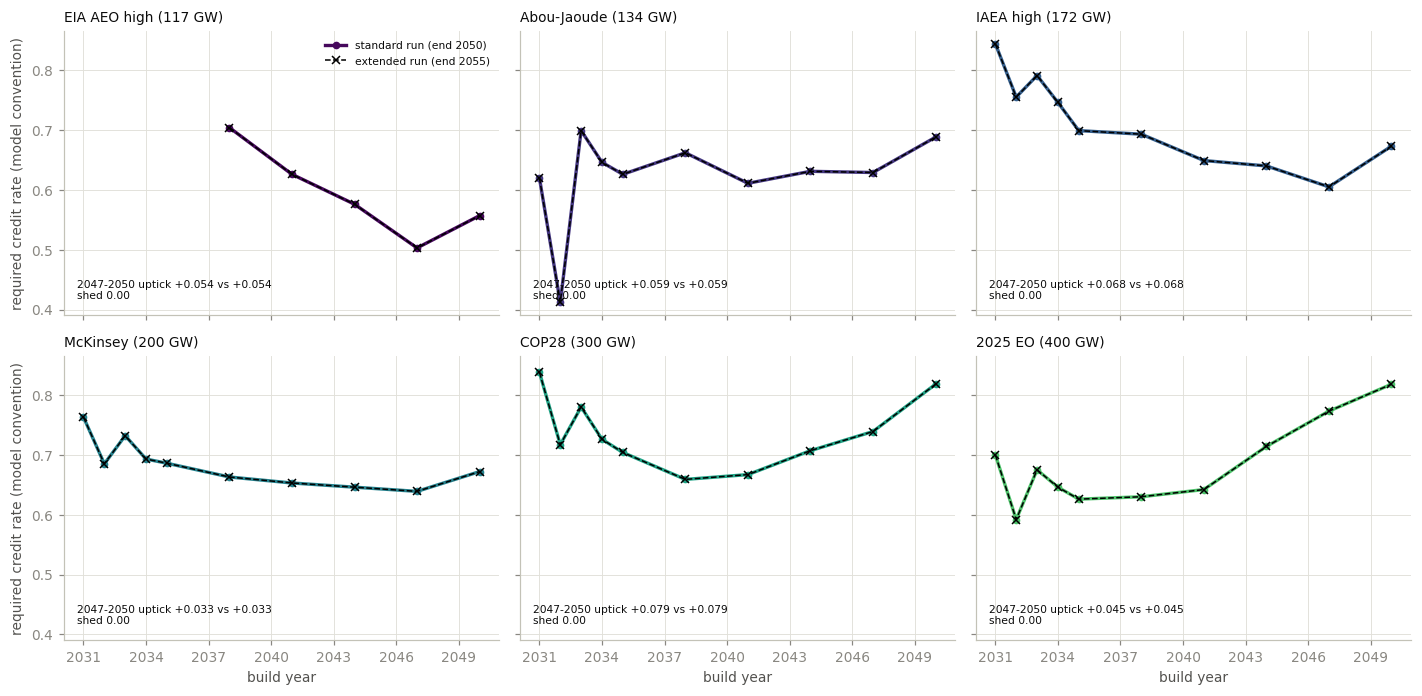

saved -> figures\w53_ga_anchors.png


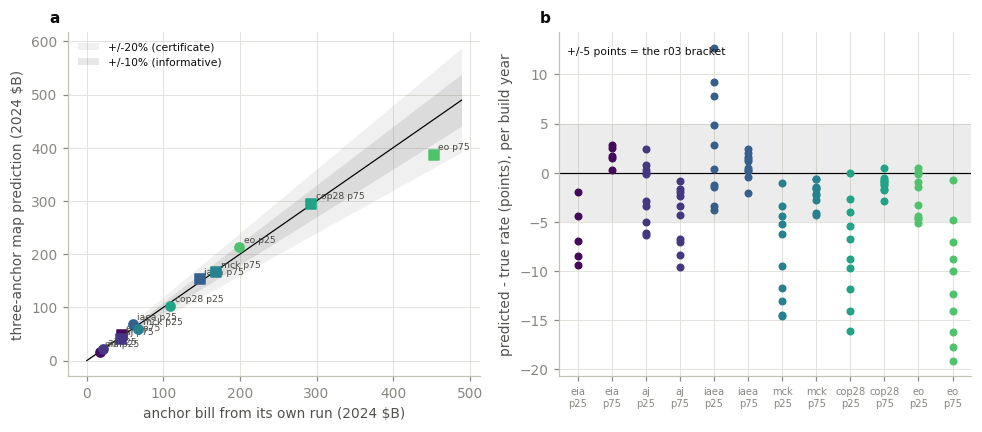

In [12]:
t09hz = pd.read_csv(CHECKS_RD / "t09_required_itc_hz.csv")
fig, axes = plt.subplots(2, 3, figsize=(ps.W3, 6.4), sharex=True, sharey=True)
for ax, ab in zip(axes.flat, SCHEDULES):
    a = t09[(t09["case"] == f"smr100_{ab}_p50") & (t09["status"] == "rate")].sort_values("t")
    h = t09hz[(t09hz["case"] == f"hz_{ab}_p50_ext") & (t09hz["status"] == "rate")].sort_values("t")
    ax.plot(a["t"], a["i_model_headline"], color=ps.SCHED_C[ab], lw=2.2, marker="o", ms=4, label="standard run (end 2050)")
    ax.plot(h["t"], h["i_model_headline"], color="k", lw=1.0, ls="--", marker="x", ms=5, label="extended run (end 2055)")
    row = u106[u106["schedule"] == ab].iloc[0]
    ax.text(0.03, 0.05, f"2047-2050 uptick {row.uptick_std:+.3f} vs {row.uptick_ext:+.3f}\nshed {row.shed_fraction:.2f}",
            transform=ax.transAxes, fontsize=7, va="bottom")
    ax.set_title(ps.SCHED_LABEL[ab], fontsize=9)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
for ax in axes[1]:
    ax.set_xlabel("build year")
for ax in axes[:, 0]:
    ax.set_ylabel("required credit rate (model convention)")
axes.flat[0].legend(fontsize=7)
fig.tight_layout()
ps.savefig(fig, FIGURES / "w52_gx1_horizon.png")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(ps.W2, 4.0))
ax = axes[0]
for r in u104.itertuples():
    ax.scatter(r.true_bill_2024B, r.pred_bill_2024B, color=ps.SCHED_C[r.schedule], s=36,
               marker=("o" if r.percentile == "p25" else "s"), zorder=3)
    ax.annotate(f"{r.schedule} {r.percentile}", (r.true_bill_2024B, r.pred_bill_2024B), xytext=(3, 3),
                textcoords="offset points", fontsize=6, color=ps.BASE_C)
lim = [0, u104[["true_bill_2024B", "pred_bill_2024B"]].max().max() * 1.08]
ax.plot(lim, lim, color="k", lw=0.8)
ax.fill_between(lim, [0.8 * l for l in lim], [1.2 * l for l in lim], color=ps.BASE_C, alpha=0.08, lw=0, label="+/-20% (certificate)")
ax.fill_between(lim, [0.9 * l for l in lim], [1.1 * l for l in lim], color=ps.BASE_C, alpha=0.12, lw=0, label="+/-10% (informative)")
ax.set_xlabel("anchor bill from its own run (2024 $B)")
ax.set_ylabel("three-anchor map prediction (2024 $B)")
ax.legend(fontsize=7, loc="upper left")
ax = axes[1]
for k, r in enumerate(u104.itertuples()):
    e = r105[r105["run"] == r.run]
    ax.scatter([k] * len(e), e["err_ratepts"], color=ps.SCHED_C[r.schedule], s=18, zorder=3)
ax.axhspan(-5, 5, color=ps.BASE_C, alpha=0.10, lw=0)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(range(len(u104)))
ax.set_xticklabels([f"{r.schedule}\n{r.percentile}" for r in u104.itertuples()], fontsize=6.5)
ax.set_ylabel("predicted - true rate (points), per build year")
ax.text(0.02, 0.96, "+/-5 points = the r03 bracket", transform=ax.transAxes, fontsize=7, va="top")
ps.letter_panels(axes)
fig.tight_layout()
ps.savefig(fig, FIGURES / "w53_ga_anchors.png")
plt.show()


saved -> figures\w54_mask_three_vs_five.png


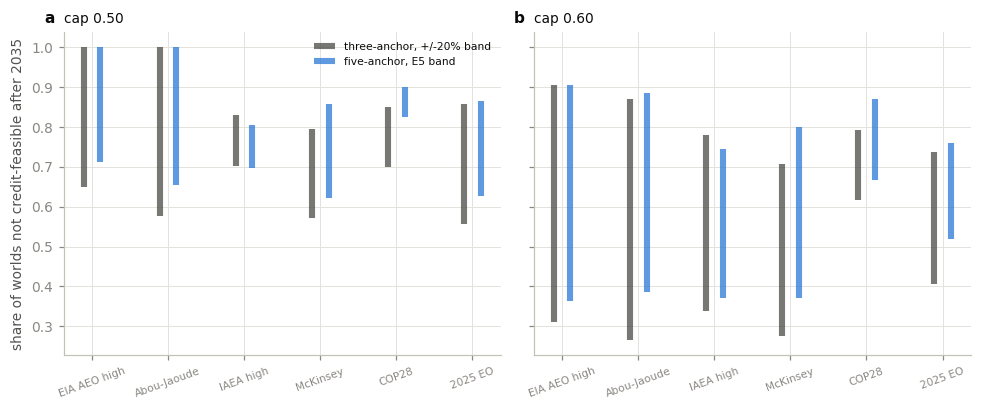

In [13]:
u51_5a = EXPORTS / "u51_feasibility_mask_5a.csv"
if u51_5a.exists():
    m3 = pd.read_csv(EXPORTS / "u51_feasibility_mask.csv")
    m5 = pd.read_csv(u51_5a)
    def rng(m):
        w = m[(m["kind"] == "per_world") & (m["window"] == "w2035")] if "kind" in m.columns else m
        return (w.groupby(["schedule", "cap"])["share_not_credit_feasible"].agg(["min", "max"]))
    r3, r5 = rng(m3), rng(m5)
    fig, axes = plt.subplots(1, 2, figsize=(ps.W2, 3.8), sharey=True)
    for ax, cap in zip(axes, [0.5, 0.6]):
        x = np.arange(len(SCHEDULES))
        for off, (lab, rr, col) in enumerate([("three-anchor, +/-20% band", r3, ps.BASE_C),
                                              ("five-anchor, E5 band", r5, ps.ACCENT["blue"])]):
            lo = [float(rr.loc[(ab, cap), "min"]) for ab in SCHEDULES]
            hi = [float(rr.loc[(ab, cap), "max"]) for ab in SCHEDULES]
            ax.vlines(x + (off - 0.5) * 0.22, lo, hi, color=col, lw=4, alpha=0.75, label=lab)
        ax.set_xticks(x)
        ax.set_xticklabels([ps.SCHED_SHORT[ab] for ab in SCHEDULES], fontsize=7, rotation=20)
        ax.set_title(f"cap {cap:.2f}", fontsize=9)
    axes[0].set_ylabel("share of worlds not credit-feasible after 2035")
    axes[0].legend(fontsize=7)
    ps.letter_panels(axes)
    fig.tight_layout()
    ps.savefig(fig, FIGURES / "w54_mask_three_vs_five.png")
    plt.show()
else:
    print("w54 skipped: the v2 twin's u51_5a does not exist yet (second run)")


In [14]:
# manifest
for p in sorted(EXPORTS.glob("u10[0-9]_*.csv")) + sorted(FIGURES.glob("w5[0-9]_*.png")):
    print(f"{p.relative_to(HERE)}  ({p.stat().st_size / 1024:.0f} kB)")


exports\u100_gate_table.csv  (8 kB)
exports\u101_verdict.csv  (6 kB)
exports\u102_ge2_depth.csv  (2 kB)
exports\u103_gh2_cap_depth.csv  (2 kB)
exports\u104_ga2_bills.csv  (1 kB)
exports\u105_ga3_rates.csv  (6 kB)
exports\u106_gx1.csv  (1 kB)
exports\u107_five_anchor_summary.csv  (0 kB)
figures\w50_delivery_ladders.png  (281 kB)
figures\w51_cap_ladder.png  (123 kB)
figures\w52_gx1_horizon.png  (426 kB)
figures\w53_ga_anchors.png  (243 kB)
figures\w54_mask_three_vs_five.png  (117 kB)
